# ML & Data analysis

In [ ]:
import sys
sys.path.append('..')

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from dotenv import load_dotenv
import os

In [2]:

load_dotenv()

USER_NAME = os.getenv("USER_NAME")
PASSWORD = os.getenv("PASSWORD")
HOST = os.getenv("HOST")
PORT = os.getenv("PORT")
DB_NAME = os.getenv("DB_NAME")

DATABASE_URL = rf"postgresql+psycopg2://{USER_NAME}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}"
engine = create_engine(DATABASE_URL)


In [3]:
sql = 'SELECT * FROM warehouse.vw_warehouse_sales; '
data = pd.read_sql(sql, con=engine)

In [4]:
print(data.shape)
data.head()

(7784, 17)


,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id
0,1,1,2020-01-01,Rice - Basmati,1153.0,21.84,2915.0,1242.0,29.29,8589.85,5362.48,33771.37,0.28,0.2544,0.0000,False,20261002135808273756
1,2,2,2020-01-08,Rice - Basmati,1108.0,21.69,3307.0,1149.0,27.30,6215.88,3593.65,30248.40,0.38,0.2055,-0.1043,False,20261002135808273756
2,3,3,2020-01-15,Rice - Basmati,1527.0,22.38,3280.0,1639.0,27.48,7787.70,2713.53,41961.96,0.46,0.1856,0.3872,False,20261002135808273756
3,4,4,2020-01-22,Rice - Basmati,1299.0,21.41,1981.0,1093.0,26.56,6689.85,2756.27,34501.44,0.40,0.1939,-0.1778,False,20261002135808273756
4,5,5,2020-01-29,Rice - Basmati,1346.0,21.69,3135.0,1424.0,26.27,6164.68,1804.61,35359.42,0.68,0.1743,0.0249,False,20261002135808273756


In [5]:
products = data['product'].unique()
print(len(products))
products

30


<StringArray>
[       'Rice - Basmati',          'Rice - White',      'Wheat - Hard Red',
          'Wheat - Soft', 'Sugar - White Refined',     'Sugar - Raw Brown',
         'Sunflower Oil',              'Palm Oil',           'Soybean Oil',
                  'Corn',                'Barley',         'Lentils - Red',
       'Lentils - Green',             'Chickpeas',   'Milk Powder - Whole',
 'Milk Powder - Skimmed',    'Tea - Black Ceylon',           'Tea - Green',
      'Coffee - Arabica',      'Coffee - Robusta',          'Cocoa Powder',
           'Canned Tuna',       'Canned Tomatoes',     'Pasta - Spaghetti',
   'Flour - All Purpose',                  'Oats',        'Salt - Iodized',
           'Yeast - Dry', 'Spices - Black Pepper',     'Spices - Turmeric']
Length: 30, dtype: str

In [6]:
pr_oi = 'Rice - Basmati'
r_basmati_data = data[data['product'] == pr_oi]
pr_oi = 'Rice - White'
r_white_data = data[data['product'] == pr_oi]

In [7]:
r_basmati_data['week'].min(), r_basmati_data['week'].max()

(np.int64(1), np.int64(260))

In [8]:
import matplotlib.pyplot as plt

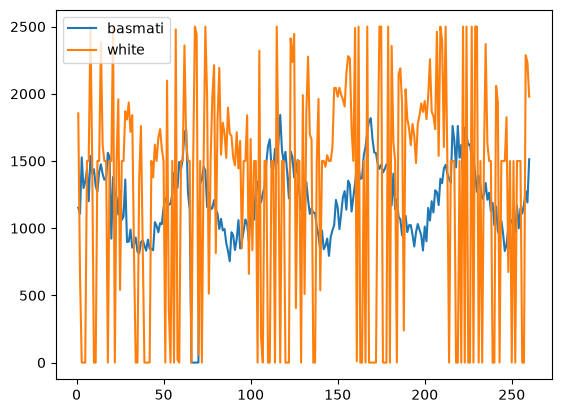

In [9]:
plt.plot(r_basmati_data['week'], r_basmati_data['sales_units'], label='basmati')
plt.plot(r_white_data['week'], r_white_data['sales_units'], label='white')
plt.legend()

In [10]:
r_white_data[r_white_data['sales_units']==0]

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id
262,263,3,2020-01-15,Rice - White,0.0,45.04,0.0,1428.0,54.95,0.0,0.0,0.0,0.0,0.0,-1.0,False,20261002135808273756
263,264,4,2020-01-22,Rice - White,0.0,47.34,0.0,2161.0,59.64,0.0,0.0,0.0,0.0,0.0,0.0,False,20261002135808273756
264,265,5,2020-01-29,Rice - White,0.0,46.93,1500.0,2336.0,58.05,0.0,0.0,0.0,0.0,0.0,0.0,False,20261002135808273756
269,270,10,2020-03-04,Rice - White,0.0,47.20,0.0,3007.0,57.27,0.0,0.0,0.0,0.0,0.0,-1.0,False,20261002135808273756
270,271,11,2020-03-11,Rice - White,0.0,46.45,1500.0,2110.0,59.52,0.0,0.0,0.0,0.0,0.0,0.0,False,20261002135808273756
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503,503,243,2024-08-21,Rice - White,0.0,45.93,1500.0,1826.0,60.59,0.0,0.0,0.0,0.0,0.0,-1.0,False,20261002135808273756
510,510,250,2024-10-09,Rice - White,0.0,48.65,1500.0,1703.0,60.89,0.0,0.0,0.0,0.0,0.0,-1.0,False,20261002135808273756
512,512,252,2024-10-23,Rice - White,0.0,47.08,1500.0,1754.0,60.63,0.0,0.0,0.0,0.0,0.0,-1.0,False,20261002135808273756
516,516,256,2024-11-20,Rice - White,0.0,47.54,0.0,2258.0,63.44,0.0,0.0,0.0,0.0,0.0,-1.0,False,20261002135808273756


- week based

In [11]:
week1_data  = data[data['week']==1]
week1_data

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id
0,1,1,2020-01-01,Rice - Basmati,1153.0,21.84,2915.0,1242.0,29.29,8589.85,5362.48,33771.37,0.28,0.2544,0.0,False,20261002135808273756
260,261,1,2020-01-01,Rice - White,1854.0,46.66,645.0,1880.0,56.18,17650.08,8894.68,104157.72,0.74,0.1695,0.0,False,20261002135808273756
521,521,1,2020-01-01,Wheat - Hard Red,541.0,38.31,2033.0,603.0,46.41,4382.10,1941.99,25107.81,0.21,0.1745,0.0,False,20261002135808273756
780,781,1,2020-01-01,Wheat - Soft,2352.0,31.09,3892.0,2095.0,41.00,23308.32,13507.70,96432.00,0.50,0.2417,0.0,False,20261002135808273756
1040,1041,1,2020-01-01,Sugar - White Refined,3012.0,11.94,2523.0,3007.0,14.49,7680.60,3496.83,43643.88,0.75,0.1760,0.0,False,20261002135808273756
1300,1301,1,2020-01-01,Sugar - Raw Brown,1745.0,12.11,3831.0,1763.0,15.05,5130.30,2846.05,26262.25,0.43,0.1953,0.0,False,20261002135808273756
1559,1560,1,2020-01-01,Sunflower Oil,732.0,7.71,3900.0,773.0,10.35,1932.48,1317.23,7576.20,0.34,0.2551,0.0,False,20261002135808273756
1819,1820,1,2020-01-01,Palm Oil,2025.0,45.70,45.0,2066.0,59.56,28066.50,14779.34,120609.00,0.98,0.2327,0.0,True,20261002135808273756
2079,2080,1,2020-01-01,Soybean Oil,2290.0,30.68,1930.0,2451.0,41.22,24136.60,13953.73,94393.80,0.84,0.2557,0.0,False,20261002135808273756
2337,2338,1,2020-01-01,Corn,2108.0,36.12,2550.0,2252.0,47.07,23082.60,13198.07,99223.56,0.45,0.2326,0.0,False,20261002135808273756


- ran out of inv

In [12]:
con1=data['sales_units'] == data['inventory_level']
con2=data['sales_units'] != 0

# data[con1 & con2]
data[ con1]

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id
65,66,66,2021-03-31,Rice - Basmati,0.0,21.82,0.0,1562.0,28.84,0.0,0.00,0.0,0.0,0.0000,-1.0000,False,20261002135808273756
66,67,67,2021-04-07,Rice - Basmati,0.0,22.48,0.0,2066.0,29.77,0.0,0.00,0.0,0.0,0.0000,0.0000,True,20261002135808273756
67,68,68,2021-04-14,Rice - Basmati,0.0,21.59,0.0,1475.0,26.09,0.0,0.00,0.0,0.0,0.0000,0.0000,False,20261002135808273756
68,69,69,2021-04-21,Rice - Basmati,0.0,21.57,0.0,1693.0,26.66,0.0,0.00,0.0,0.0,0.0000,0.0000,False,20261002135808273756
262,263,3,2020-01-15,Rice - White,0.0,45.04,0.0,1428.0,54.95,0.0,0.00,0.0,0.0,0.0000,-1.0000,False,20261002135808273756
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7494,7495,231,2024-05-29,Spices - Black Pepper,1500.0,31.68,1500.0,2647.0,41.56,14820.0,8243.87,62340.0,1.0,0.2377,-0.4177,False,20261002135808273756
7495,7496,232,2024-06-05,Spices - Black Pepper,1500.0,32.13,1500.0,3041.0,42.77,15960.0,9374.16,64155.0,1.0,0.2488,0.0291,False,20261002135808273756
7497,7498,234,2024-06-19,Spices - Black Pepper,0.0,31.82,0.0,2442.0,40.62,0.0,0.00,0.0,0.0,0.0000,-1.0000,False,20261002135808273756
7498,7499,235,2024-06-26,Spices - Black Pepper,0.0,31.57,0.0,2066.0,40.75,0.0,0.00,0.0,0.0,0.0000,0.0000,True,20261002135808273756


# method 1

In [13]:
import numpy as np
import pandas as pd

from sqlalchemy import create_engine
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [14]:
df = data

In [15]:
df["week"] = pd.to_numeric(df["week"])
df["sales_units"] = pd.to_numeric(df["sales_units"])
df["demand_forecast"] = pd.to_numeric(df["demand_forecast"])

df["start_date"] = pd.to_datetime(df["start_date"])

df = df.sort_values(
    ["product", "week"]
).reset_index(drop=True)



In [16]:
# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

TRAIN_END = 234
TEST_START = 235
TEST_END = 260

train = df[
    df["week"] <= TRAIN_END
].copy()

test = df[
    (df["week"] >= TEST_START) &
    (df["week"] <= TEST_END)
].copy()


print("Number of products:", df["product"].nunique())
print("Training weeks:", train["week"].min(), "-", train["week"].max())
print("Test weeks:", test["week"].min(), "-", test["week"].max())
print("Training rows:", len(train))
print("Test rows:", len(test))


Number of products: 30
Training weeks: 1 - 234
Test weeks: 235 - 260
Training rows: 7004
Test rows: 780


In [17]:
# ============================================================
# 5. TIME-SERIES FEATURE ENGINEERING
# ============================================================

def create_features(data):
    """
    Create lag, rolling and calendar features.

    IMPORTANT:
    All lag/rolling features are based only on historical
    sales_units values.
    """

    data = data.copy()

    data = data.sort_values(
        ["product", "week"]
    )

    grouped = data.groupby(
        "product",
        group_keys=False
    )

    # --------------------------------------------------------
    # Lag features
    # --------------------------------------------------------

    lag_periods = [
        1,
        2,
        4,
        8,
        13,
        26
    ]

    for lag in lag_periods:

        data[f"lag_{lag}"] = grouped[
            "sales_units"
        ].shift(lag)


    # --------------------------------------------------------
    # Rolling features
    #
    # Shift first so the current week's sales are NOT used.
    # --------------------------------------------------------

    shifted_sales = grouped["sales_units"].shift(1)

    data["rolling_mean_4"] = (
        shifted_sales
        .groupby(data["product"])
        .transform(
            lambda x: x.rolling(4).mean()
        )
    )

    data["rolling_mean_8"] = (
        shifted_sales
        .groupby(data["product"])
        .transform(
            lambda x: x.rolling(8).mean()
        )
    )

    data["rolling_mean_13"] = (
        shifted_sales
        .groupby(data["product"])
        .transform(
            lambda x: x.rolling(13).mean()
        )
    )

    data["rolling_mean_26"] = (
        shifted_sales
        .groupby(data["product"])
        .transform(
            lambda x: x.rolling(26).mean()
        )
    )

    data["rolling_std_8"] = (
        shifted_sales
        .groupby(data["product"])
        .transform(
            lambda x: x.rolling(8).std()
        )
    )


    # --------------------------------------------------------
    # Exponentially weighted moving average
    # --------------------------------------------------------

    data["ewm_8"] = (
        shifted_sales
        .groupby(data["product"])
        .transform(
            lambda x: x.ewm(
                span=8,
                adjust=False
            ).mean()
        )
    )


    # --------------------------------------------------------
    # Calendar / seasonal features
    # --------------------------------------------------------

    data["week_sin"] = np.sin(
        2 * np.pi * data["week"] / 52
    )

    data["week_cos"] = np.cos(
        2 * np.pi * data["week"] / 52
    )


    # --------------------------------------------------------
    # Product encoding
    # --------------------------------------------------------

    data["product_code"] = (
        data["product"]
        .astype("category")
        .cat.codes
    )


    return data


In [18]:
# ============================================================
# 6. CREATE FEATURES
# ============================================================

featured = create_features(df)


In [19]:
feature_columns = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "lag_13",
    "lag_26",

    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_mean_13",
    "rolling_mean_26",
    "rolling_std_8",

    "ewm_8",

    "week_sin",
    "week_cos",

    "product_code",
]



In [20]:
model_train = featured[
    featured["week"] <= TRAIN_END
].copy()

model_train = model_train.dropna(
    subset=feature_columns + ["sales_units"]
)


X_train = model_train[
    feature_columns
]

y_train = model_train[
    "sales_units"
]


print(
    "Rows used for model training:",
    len(model_train)
)


Rows used for model training: 6224


In [21]:
model = RandomForestRegressor(
    n_estimators=500,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [22]:
forecast_history = df[
    df["week"] <= TRAIN_END
].copy()

forecast_rows = []



In [23]:
for week in range(TEST_START, TEST_END + 1):

    current_rows = []

    for product in df["product"].unique():

        product_history = forecast_history[
            forecast_history["product"] == product
        ].sort_values("week").copy()

        sales_history = (
            product_history["sales_units"]
            .dropna()
            .tolist()
        )

        # ----------------------------------------------------
        # Create one future row
        # ----------------------------------------------------

        row = {
            "week": week,
            "product": product,
        }


        # ----------------------------------------------------
        # Lag features
        # ----------------------------------------------------

        row["lag_1"] = (
            sales_history[-1]
            if len(sales_history) >= 1
            else np.nan
        )

        row["lag_2"] = (
            sales_history[-2]
            if len(sales_history) >= 2
            else np.nan
        )

        row["lag_4"] = (
            sales_history[-4]
            if len(sales_history) >= 4
            else np.nan
        )

        row["lag_8"] = (
            sales_history[-8]
            if len(sales_history) >= 8
            else np.nan
        )

        row["lag_13"] = (
            sales_history[-13]
            if len(sales_history) >= 13
            else np.nan
        )

        row["lag_26"] = (
            sales_history[-26]
            if len(sales_history) >= 26
            else np.nan
        )


        # ----------------------------------------------------
        # Rolling features
        # ----------------------------------------------------

        row["rolling_mean_4"] = np.mean(
            sales_history[-4:]
        )

        row["rolling_mean_8"] = np.mean(
            sales_history[-8:]
        )

        row["rolling_mean_13"] = np.mean(
            sales_history[-13:]
        )

        row["rolling_mean_26"] = np.mean(
            sales_history[-26:]
        )

        row["rolling_std_8"] = np.std(
            sales_history[-8:],
            ddof=1
        )


        # ----------------------------------------------------
        # Exponential moving average
        # ----------------------------------------------------

        row["ewm_8"] = (
            pd.Series(sales_history)
            .ewm(
                span=8,
                adjust=False
            )
            .mean()
            .iloc[-1]
        )


        # ----------------------------------------------------
        # Seasonal features
        # ----------------------------------------------------

        row["week_sin"] = np.sin(
            2 * np.pi * week / 52
        )

        row["week_cos"] = np.cos(
            2 * np.pi * week / 52
        )


        # ----------------------------------------------------
        # Product encoding
        # ----------------------------------------------------

        product_codes = (
            df["product"]
            .astype("category")
            .cat
        )

        row["product_code"] = (
            product_codes
            .categories
            .get_loc(product)
        )


        current_rows.append(row)


    future_features = pd.DataFrame(
        current_rows
    )


    # --------------------------------------------------------
    # Predict this week
    # --------------------------------------------------------

    X_future = future_features[
        feature_columns
    ]

    predictions = model.predict(
        X_future
    )

    future_features["predicted_sales_units"] = (
        predictions
    )


    # --------------------------------------------------------
    # Add predictions to history
    #
    # This is what makes the forecast recursive.
    # For week 236, lag_1 can therefore use our prediction
    # for week 235.
    # --------------------------------------------------------

    new_history = future_features[
        [
            "week",
            "product",
            "predicted_sales_units"
        ]
    ].rename(
        columns={
            "predicted_sales_units":
                "sales_units"
        }
    )

    forecast_history = pd.concat(
        [
            forecast_history,
            new_history
        ],
        ignore_index=True
    )


    forecast_rows.append(
        future_features
    )


# Combine all 26 forecast weeks
forecast = pd.concat(
    forecast_rows,
    ignore_index=True
)


# ============================================================
# 11. GET ACTUAL VALUES
# ============================================================

actuals = test[
    [
        "week",
        "product",
        "sales_units",
        "demand_forecast"
    ]
].copy()


results = forecast.merge(
    actuals,
    on=["week", "product"],
    how="left"
)


# ============================================================
# 12. BASELINE MODELS
# ============================================================

# ------------------------------------------------------------
# A. Demand Forecast baseline
# ------------------------------------------------------------

results["baseline_demand_forecast"] = (
    results["demand_forecast"]
)


# ------------------------------------------------------------
# B. Naive forecast
#
# Predict every future week using the final observed
# sales value from week 234.
# ------------------------------------------------------------

last_sales = (
    train
    .sort_values("week")
    .groupby("product")["sales_units"]
    .last()
    .rename("last_sales")
)

results = results.merge(
    last_sales,
    on="product",
    how="left"
)

results["baseline_naive"] = (
    results["last_sales"]
)


# ------------------------------------------------------------
# C. Seasonal naive
#
# Predict week t using sales from t-26.
# ------------------------------------------------------------

seasonal_lookup = df[
    ["product", "week", "sales_units"]
].copy()

seasonal_lookup["week"] = (
    seasonal_lookup["week"] + 26
)

seasonal_lookup = seasonal_lookup.rename(
    columns={
        "sales_units":
            "baseline_seasonal_26"
    }
)

results = results.merge(
    seasonal_lookup[
        [
            "product",
            "week",
            "baseline_seasonal_26"
        ]
    ],
    on=["product", "week"],
    how="left"
)



In [24]:
# ============================================================
# 13. METRIC FUNCTIONS
# ============================================================

def rmse(actual, predicted):
    return np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )


def mae(actual, predicted):
    return mean_absolute_error(
        actual,
        predicted
    )


def smape(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    denominator = (
        np.abs(actual) +
        np.abs(predicted)
    )

    mask = denominator != 0

    return (
        100 *
        np.mean(
            2 *
            np.abs(
                predicted[mask] -
                actual[mask]
            ) /
            denominator[mask]
        )
    )




In [25]:

models = {
    "Random Forest": "predicted_sales_units",
    "Demand Forecast": "baseline_demand_forecast",
    "Naive": "baseline_naive",
    "Seasonal Naive 26": "baseline_seasonal_26",
}


In [26]:
metrics = []

In [27]:
for model_name, prediction_column in models.items():

    evaluation = results[
        [
            "sales_units",
            prediction_column
        ]
    ].dropna()

    actual = evaluation["sales_units"]
    predicted = evaluation[prediction_column]

    metrics.append(
        {
            "model": model_name,
            "RMSE": rmse(
                actual,
                predicted
            ),
            "MAE": mae(
                actual,
                predicted
            ),
            "sMAPE": smape(
                actual,
                predicted
            ),
        }
    )


metrics_df = pd.DataFrame(
    metrics
)


# ============================================================
# 15. DISPLAY OVERALL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("OVERALL FORECAST PERFORMANCE")
print("=" * 70)

print(
    metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}"
    )
)


# ============================================================
# 16. METRICS BY PRODUCT
# ============================================================

product_metrics = []


for product, product_data in results.groupby("product"):

    actual = product_data[
        "sales_units"
    ]

    for model_name, prediction_column in models.items():

        mask = (
            actual.notna() &
            product_data[
                prediction_column
            ].notna()
        )

        actual_values = actual[mask]
        predicted_values = product_data.loc[
            mask,
            prediction_column
        ]

        product_metrics.append(
            {
                "product": product,
                "model": model_name,
                "RMSE": rmse(
                    actual_values,
                    predicted_values
                ),
                "MAE": mae(
                    actual_values,
                    predicted_values
                ),
                "sMAPE": smape(
                    actual_values,
                    predicted_values
                ),
            }
        )


product_metrics_df = pd.DataFrame(
    product_metrics
)


# ============================================================
# 17. SHOW PRODUCT-LEVEL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("PER-PRODUCT FORECAST PERFORMANCE")
print("=" * 70)

print(
    product_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}"
    )
)


# ============================================================
# 18. FORECAST OUTPUT
# ============================================================

forecast_output = results[
    [
        "week",
        "product",
        "sales_units",
        "demand_forecast",
        "predicted_sales_units",
        "baseline_naive",
        "baseline_seasonal_26",
    ]
].sort_values(
    ["product", "week"]
)


print("\n")
print("=" * 70)
print("FIRST FORECAST RESULTS")
print("=" * 70)

print(
    forecast_output.head(30).to_string(
        index=False
    )
)




OVERALL FORECAST PERFORMANCE
            model      RMSE     MAE  sMAPE
    Random Forest   718.430 570.630 57.426
  Demand Forecast 1,077.080 682.305 49.509
            Naive   983.326 665.079 65.174
Seasonal Naive 26 1,112.271 823.019 79.587


PER-PRODUCT FORECAST PERFORMANCE
              product             model      RMSE       MAE   sMAPE
               Barley     Random Forest 1,104.467 1,016.802  87.875
               Barley   Demand Forecast 1,312.677   862.885  57.378
               Barley             Naive   920.319   792.077  67.064
               Barley Seasonal Naive 26 1,155.866   946.308  85.066
      Canned Tomatoes     Random Forest   811.810   767.722  87.270
      Canned Tomatoes   Demand Forecast 1,134.812   772.346  65.485
      Canned Tomatoes             Naive 1,481.237 1,245.500 200.000
      Canned Tomatoes Seasonal Naive 26 1,198.897   936.958 100.095
          Canned Tuna     Random Forest   967.828   889.776  89.546
          Canned Tuna   Demand Forecast

In [28]:
# ============================================================
# 19. OPTIONAL: SAVE RESULTS LOCALLY
# ============================================================

forecast_output.to_csv(
    "forecast_results.csv",
    index=False
)

metrics_df.to_csv(
    "forecast_metrics.csv",
    index=False
)

product_metrics_df.to_csv(
    "forecast_metrics_by_product.csv",
    index=False
)


print("\nForecast files saved:")
print("  forecast_results.csv")
print("  forecast_metrics.csv")
print("  forecast_metrics_by_product.csv")



Forecast files saved:
  forecast_results.csv
  forecast_metrics.csv
  forecast_metrics_by_product.csv
